Follow the war-photo-recall data through analysis, fitting, simulation and comparison. The first sections identify the settings and outputs in each template; the final section executes the same sequence with Papermill, including a separate fitting run for each model. It reuses the supplied completed fits by default.

Use the repository and environment from [Developer Setup](../developer-setup.ipynb). Open this notebook in that environment. The repository contains the observations and completed fits; no lab-drive files are needed. For preparing your own inputs, start with [Preparing data for JAXCMR](data-preparation.ipynb).

In [1]:
#| code-summary: "1 — Configure the tutorial work units"

project_root = None  # The JAXCMR checkout; set explicitly when working elsewhere.
output_dir = "results/tutorial/model-comparison"
data_path = "data/Dupertuys2026.h5"

fit_sources = {
    "CMR": "data/fits/Dupertuys2026_CMR_demo.json",
    "eCMR_source_only": "data/fits/Dupertuys2026_eCMR_source_only.json",
    "eCMR_broad": "data/fits/Dupertuys2026_eCMR_broad.json",
}
model_labels = {
    "CMR": "CMR",
    "eCMR_source_only": "Source-only eCMR",
    "eCMR_broad": "Broader eCMR",
}
redo_fits = False  # True launches the full recorded optimization settings.
experiment_count = 10
simulation_seed = 1
trial_queries = ["data['list_type'] == 1", "data['list_type'] == 2", "data['list_type'] == 3"]
labels = ["Mixed", "Pure emotional", "Pure neutral"]


## Describe observed recall

Open [Serial position curves](../templates/spc.ipynb). In its parameter cell, set `data_paths = ["data/Dupertuys2026.h5"]`, `data_labels = ["Observed"]` and `output_dir = "results/tutorial/model-comparison/observed"`. Leave the single-input override `data_path` unset. Retain the three `trial_queries` and matching `labels` shown above.

Run the notebook. It reports 491 complete lists from 123 participants, excluding the one padded study list, and produces one condition panel per query. The saved figure is `observed/spc.png` beneath this tutorial's output folder. The vertical axis describes recall probability at each study position; the curve alone does not identify a memory mechanism.

## Inspect a fitted model

Open [Fitting models](../templates/fitting.ipynb). Its first cell collects the observation selection, model specifications, fixed/free parameters, optimizer and output settings. The three supplied specifications fit all 492 lists with pooled parameters; the analysis selection for complete lists does not change the fitting selection.

| Setting | Meaning in this example |
|---|---|
| `model_configs` | CMR, source-only eCMR and broader eCMR; use a one-entry dictionary for one model per job. |
| `parameters["fixed"]` and `parameters["free"]` inside each model | Fixed values and bounds for fitted values. |
| `fit_alg_path`, `fit_hyperparams` | Optimizer and search settings, separate from model parameters. |
| `redo_fits = False` | Load a compatible result if it exists; a missing result would still start fitting. |
| `redo_sims = False`, `redo_figures = False` | Run fitting/objective inspection only. |

The Papermill cells below place copies of the supplied fits at the expected paths before executing fitting. They display fitted parameters and independently recalculated objectives. Expected NLLs are approximately **7202.029** (CMR), **7169.426** (source-only) and **7164.358** (broader eCMR). Each fit estimates one parameter set across all participants.

To start new fits, choose a new `output_dir` and set this tour's `redo_fits = True`. That uses the full recorded SciPy DE settings: 1,000 generations, population multiplier 15 and three restarts, with the recorded bounds and seeds. It can take substantially longer than inspecting saved fits. For different scientific specifications, edit the per-job `model_configs` passed to fitting and use a new output directory.

## Generate responses from the fits

Open [Simulating from saved fits](../templates/simulation.ipynb). Supply fitting's printed `fit_paths`, set `experiment_count = 10` and `simulation_seed = 1`, and choose a `simulation_dir`. The sequence below uses a distinct folder for each model and sets `redo_sims = False`, allowing matching responses to be reused on a later run.

The first run generates 4,920 response rows per model: ten repetitions of each of the 492 lists, retaining the original 123 participant IDs and list conditions. Each `.h5` response file has a `.json` provenance sidecar. These simulations impose observed recall lengths; matching recall counts are not a successful prediction of stopping behavior.

## Compare observed and simulated recall

Return to [SPC](../templates/spc.ipynb). Supply the observation file followed by simulation's printed response paths as `data_paths`, with matching `data_labels`. Use the same condition queries and complete-list selection. Simulated repetitions stay grouped under the original participant IDs when summarizing behavior.

The sequence below writes `predictions/spc.png`: each condition panel compares observations with all three models. Other [analysis templates](../templates.qmd) can read these same saved response files without fitting or simulating again.

## Compare models

Open [Comparing pooled model fits](../templates/model_comparison.ipynb). Supply the same named `fit_paths` and `simulation_paths`. The notebook checks that the models use matching observations, objectives and stopping rules, recalculates likelihoods, and reports NLL, parameter counts, AIC, ΔAIC and search histories alongside behavioral comparisons.

The expected parameter counts are 9, 10 and 10. Lower AIC is better within this comparison, but its interpretation depends on the fitted specifications and optimization quality; these pooled results are not independent participant-level estimates. The saved table is `comparison/pooled_model_comparison.csv`.

For supported statistical examples, see [category recall rate](../templates/cat_recall_rate.ipynb) for paired participant contrasts and [distance rank](../templates/distrank.ipynb) for tests against chance. Use participant summaries as the sampling units; simulation repetitions are not additional participants.

## Sequence the templates with Papermill

[Papermill](https://papermill.readthedocs.io/en/latest/usage-execute.html) executes a notebook with a parameter dictionary and saves the executed copy. Its [parameter injection](https://papermill.readthedocs.io/en/latest/usage-parameterize.html) occurs immediately after the tagged `parameters` cell, before paths, masks and models are constructed. The templates are already tagged, and Papermill is included in `uv sync`.

The following cells form an ordinary Python script, kept here in the notebook: import packages, prepare work units, then call `pm.execute_notebook` in the required order. Each fitting call receives a different one-entry `model_configs` dictionary. Shared memory between notebooks is unnecessary: paths identify the saved products passed to the next call. The `python3` kernel must be the project's environment, as in Developer Setup.

In [3]:
#| code-summary: "2 — Import the sequencing and display tools"

import csv
import json
from pathlib import Path

from IPython.display import Image, display
import papermill as pm
from tabulate import tabulate

from jaxcmr.helpers import find_project_root, resolve_project_path


In [4]:
#| code-summary: "3 — Resolve templates and the executed-notebook folder"

if project_root is not None:
    root_path = resolve_project_path(project_root, Path.cwd())
else:
    try:
        root_path = Path(find_project_root())
    except FileNotFoundError:
        root_path = Path.cwd()
output_path = resolve_project_path(output_dir, root_path)
output_path.mkdir(parents=True, exist_ok=True)
template_path = root_path / "templates"
if not (template_path / "fitting.ipynb").is_file():
    raise FileNotFoundError("Set project_root to the JAXCMR checkout from Developer Setup.")
executed_path = output_path / "executed"
executed_path.mkdir(exist_ok=True)
observation_path = resolve_project_path(data_path, root_path)
execution_options = {"kernel_name": "python3", "cwd": str(root_path), "progress_bar": False}
analysis_parameters = {
    "project_root": str(root_path),
    "trial_queries": trial_queries,
    "labels": labels,
}


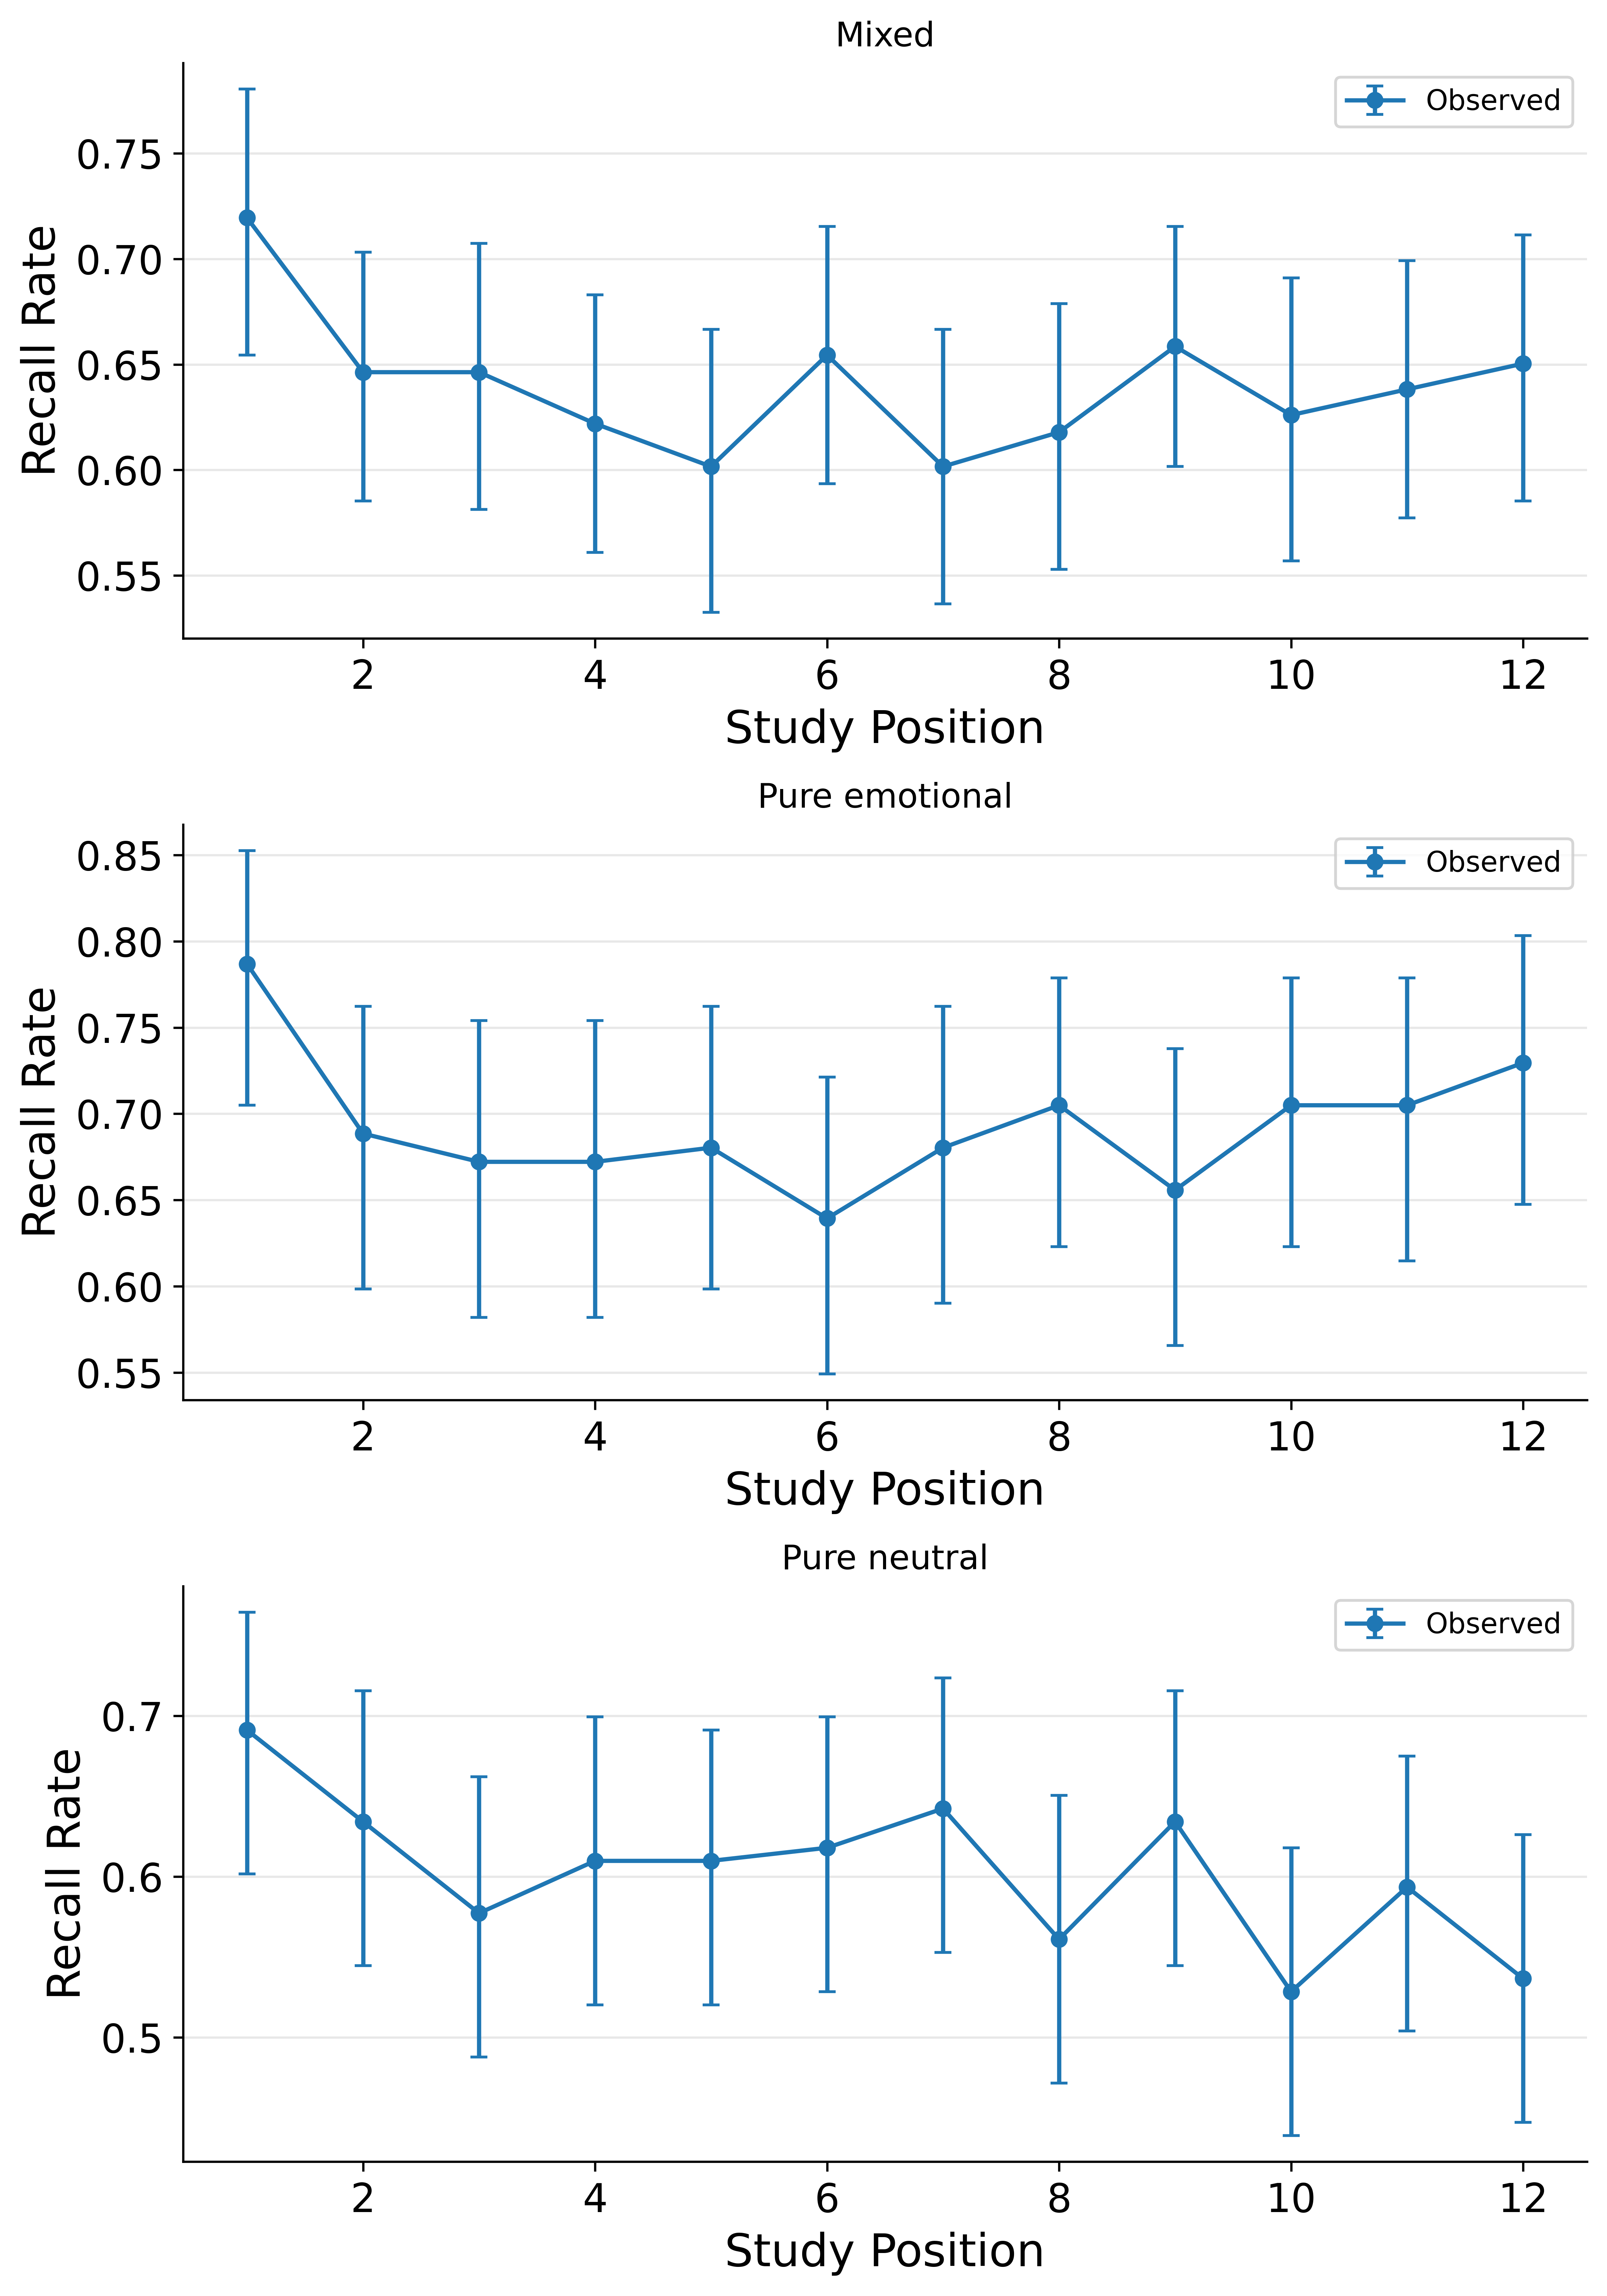

In [5]:
#| code-summary: "4 — Run the observed-data analysis"

pm.execute_notebook(
    str(template_path / "spc.ipynb"), str(executed_path / "observed_spc.ipynb"),
    parameters={
        **analysis_parameters,
        "data_paths": [str(observation_path)], "data_labels": ["Observed"],
        "output_dir": str(output_path / "observed"),
    },
    **execution_options,
)
display(Image(filename=str(output_path / "observed" / "spc.png")))


The work-unit preparation below reads the exact specifications from the supplied fit records. It copies results into this run's folder and supplies the cohort metadata omitted by the older records, using their recorded cohort indices. Original inputs are left unchanged; existing working results are not replaced.

In [6]:
#| code-summary: "5 — Prepare a separate fitting work unit for each model"

fit_jobs = []
for model_name, source in fit_sources.items():
    fit_record = json.loads(resolve_project_path(source, root_path).read_text())
    fit_record["fit_configuration"].setdefault(
        "cohort_trial_indices", fit_record["cohort_trial_indices"]
    )
    job_path = output_path / model_name
    fit_directory = job_path / "fits"
    fit_directory.mkdir(parents=True, exist_ok=True)
    fit_path = fit_directory / f"{fit_record['name']}.json"
    if not redo_fits and not fit_path.exists():
        fit_path.write_text(json.dumps(fit_record, indent=2) + "\n")

    search = fit_record["fit_configuration"]["search_settings"]
    model_spec = {
        "label": model_labels[model_name],
        "model_factory": fit_record["model_factory"],
        "components": fit_record["components"],
        "parameters": fit_record["fit_configuration"]["parameters"],
        "seed": search["seed"], "output_stem": fit_record["name"],
        "embedding_path": fit_record["embedding_path"],
        "emotion_feature_path": fit_record["emotion_feature_path"],
        "feature_column": fit_record["feature_column"],
        "concat_features": fit_record["concat_features"],
    }
    fit_jobs.append({
        "name": model_name, "directory": job_path, "fit_path": fit_path,
        "model_configs": {model_name: model_spec},
        "fit_alg_path": fit_record["fit_algorithm"],
        "fit_hyperparams": {key: value for key, value in search.items() if key not in {"seed", "bounds"}},
        "loss_fn_path": fit_record["loss_function"],
        "sim_alg_path": fit_record["simulation_function"],
        "trial_query": fit_record["trial_query"],
    })
print("Fitting work units:", [job["name"] for job in fit_jobs])


Fitting work units: ['CMR', 'eCMR_source_only', 'eCMR_broad']


In [7]:
#| code-summary: "6 — Execute the same fitting template once per model"

fit_paths = {}
for job in fit_jobs:
    model_name = job["name"]
    pm.execute_notebook(
        str(template_path / "fitting.ipynb"),
        str(executed_path / f"fit_{model_name}.ipynb"),
        parameters={
            "project_root": str(root_path), "data_path": str(observation_path),
            "model_configs": job["model_configs"],
            "fit_alg_path": job["fit_alg_path"], "fit_hyperparams": job["fit_hyperparams"],
            "loss_fn_path": job["loss_fn_path"], "sim_alg_path": job["sim_alg_path"],
            "trial_query": job["trial_query"], "pooled": True,
            "output_dir": str(job["directory"]), "fit_dir": str(job["fit_path"].parent),
            "redo_fits": redo_fits, "redo_sims": False, "redo_figures": False,
        },
        **execution_options,
    )
    fit_paths[model_name] = str(job["fit_path"])
    fitted = json.loads(job["fit_path"].read_text())
    print(model_labels[model_name], "— saved NLL:", fitted["fitness"][0])


Unable to parse line 177 '        "trial_query": "data['list_type'] == 1",'.


Unable to parse line 177 '        "trial_query": "data['list_type'] == 1",'.


CMR — saved NLL: 7202.029122199305


Unable to parse line 177 '        "trial_query": "data['list_type'] == 1",'.


Source-only eCMR — saved NLL: 7169.426270173915


Broader eCMR — saved NLL: 7164.357873171088


In [8]:
#| code-summary: "7 — Simulate from each completed fitting work unit"

simulation_paths = {}
for job in fit_jobs:
    model_name = job["name"]
    simulation_directory = job["directory"] / "simulations"
    pm.execute_notebook(
        str(template_path / "simulation.ipynb"),
        str(executed_path / f"simulate_{model_name}.ipynb"),
        parameters={
            "project_root": str(root_path), "data_path": str(observation_path),
            "fit_paths": {model_name: fit_paths[model_name]},
            "model_labels": model_labels,
            "output_dir": str(job["directory"] / "simulation"),
            "simulation_dir": str(simulation_directory),
            "experiment_count": experiment_count, "simulation_seed": simulation_seed,
            "redo_sims": False, "redo_figures": False,
        },
        **execution_options,
    )
    fitted = json.loads(Path(fit_paths[model_name]).read_text())
    simulation_paths[model_name] = str(simulation_directory / f"{fitted['name']}.h5")
print("Simulation files prepared for:", list(simulation_paths))


Unable to parse line 54 '        "trial_query": "data['list_type'] == 1",'.


Unable to parse line 54 '        "trial_query": "data['list_type'] == 1",'.


Simulation files prepared for: ['CMR', 'eCMR_source_only', 'eCMR_broad']


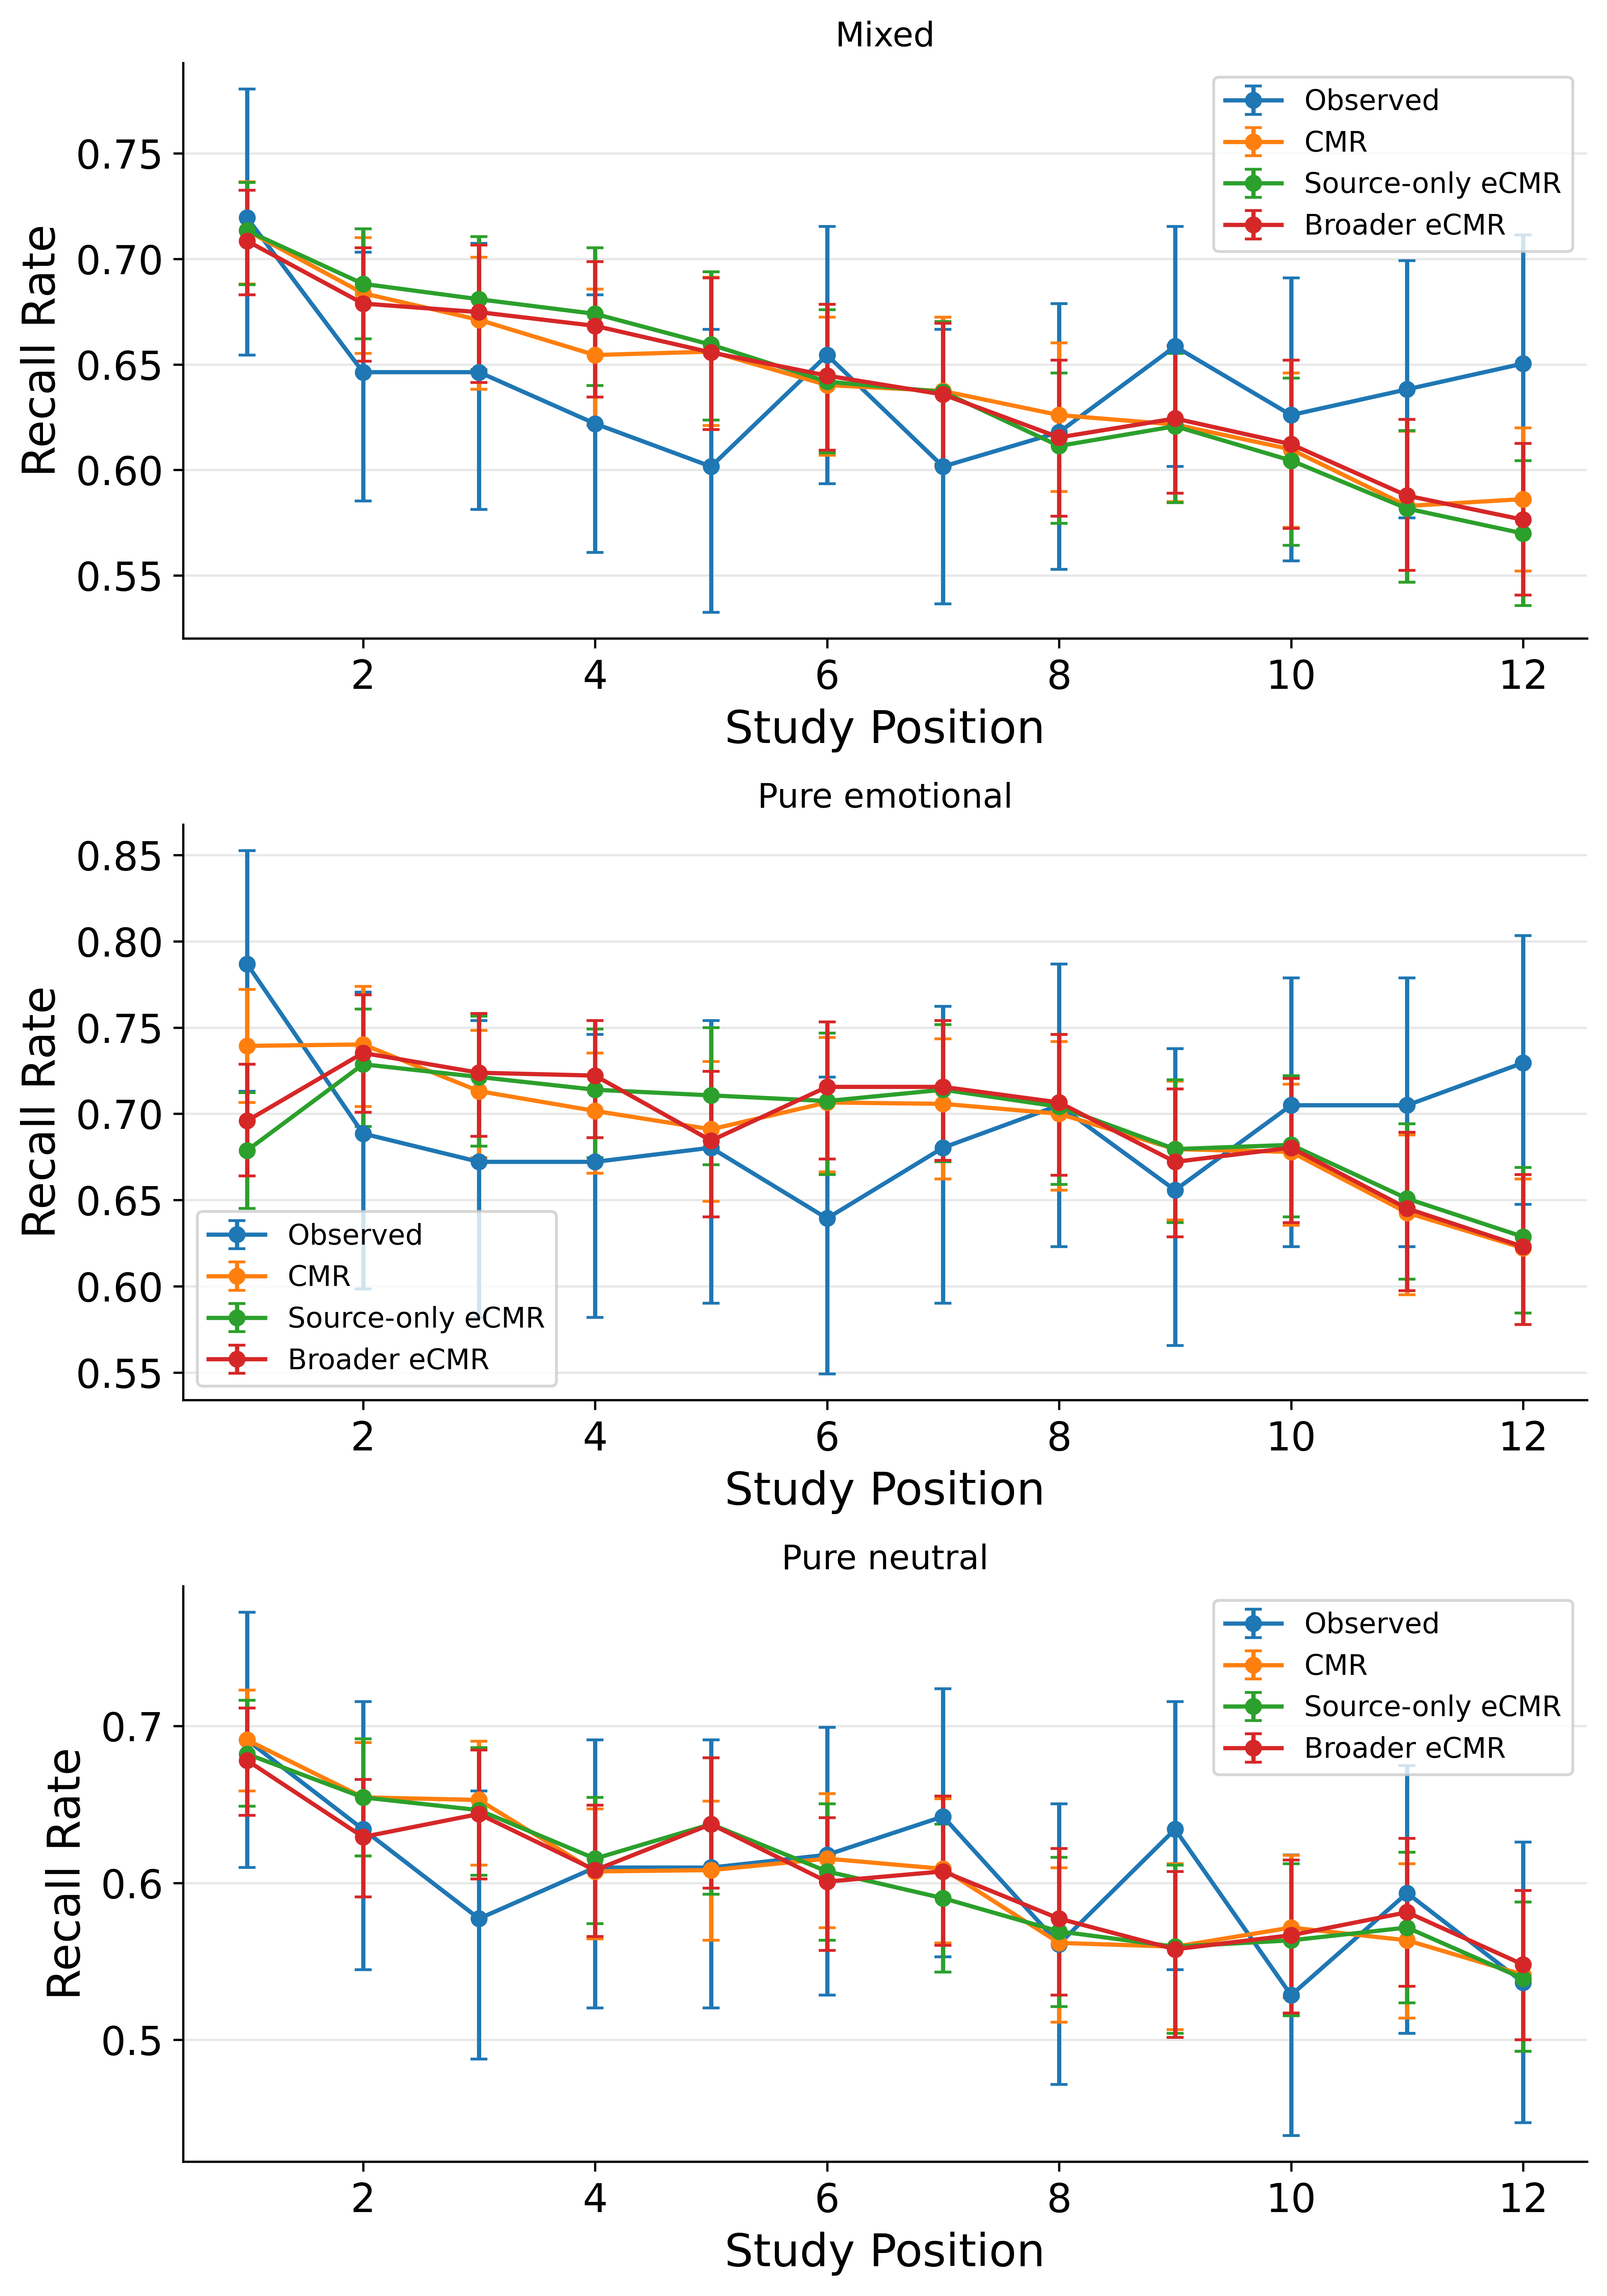

In [9]:
#| code-summary: "8 — Run SPC on the observations and saved model responses"

pm.execute_notebook(
    str(template_path / "spc.ipynb"), str(executed_path / "predicted_spc.ipynb"),
    parameters={
        **analysis_parameters,
        "data_paths": [str(observation_path), *simulation_paths.values()],
        "data_labels": ["Observed", *[model_labels[name] for name in simulation_paths]],
        "output_dir": str(output_path / "predictions"),
    },
    **execution_options,
)
display(Image(filename=str(output_path / "predictions" / "spc.png")))


In [10]:
#| code-summary: "9 — Compare the same fits and responses and display their scores"

pm.execute_notebook(
    str(template_path / "model_comparison.ipynb"),
    str(executed_path / "model_comparison.ipynb"),
    parameters={
        "project_root": str(root_path), "data_path": str(observation_path),
        "fit_paths": fit_paths, "simulation_paths": simulation_paths,
        "model_labels": model_labels, "output_dir": str(output_path / "comparison"),
    },
    **execution_options,
)
with (output_path / "comparison" / "pooled_model_comparison.csv").open(newline="") as stream:
    comparison_rows = list(csv.DictReader(stream))
print(tabulate(comparison_rows, headers="keys", floatfmt=".3f"))


Unable to parse line 48 '        "trial_query": "data['list_type'] == 1",'.


Model               Free parameters    Negative log likelihood        AIC    Delta AIC
----------------  -----------------  -------------------------  ---------  -----------
CMR                               9                   7202.029  14422.058       73.342
Source-only eCMR                 10                   7169.426  14358.853       10.137
Broader eCMR                     10                   7164.358  14348.716        0.000


Executed notebooks are under `output_dir/executed`; fit records, simulated responses, figures and summary tables remain in their named result folders. Papermill stops on an execution error, so a failed fitting job prevents the later comparison from silently continuing.

For cluster work, prepare one parameter dictionary and a distinct output notebook/path per work unit, then submit those jobs through your scheduler. Only launch the combined analyses after all required fits and simulations finish. Papermill supplies parameter injection and execution; it does not schedule cluster jobs.